# Libraries

In [1]:
import sys
sys.path.insert(0, '..')
from pythons_for_plugin.single_traj_prediction import *

from andi_datasets.datasets_challenge import challenge_theory_dataset
import torch
from pathlib import Path
import torch.nn as nn
from step.models import XResAttn
from fastai.vision.all import Learner, DataLoaders, MSELossFlat, L
import time
from torch.nn import L1Loss
from tqdm.auto import tqdm

from matplotlib import pyplot as plt

dvc = 'cuda' if torch.cuda.is_available() else 'cpu'

/home/gorka/github/andi_datasets/andi_datasets/utils_videos.py:22: UserWarning: From your imports it seems that you will need Deeptrack. Install if needed using pip install deeptrack.
  warnings.warn('From your imports it seems that you will need Deeptrack. Install if needed using pip install deeptrack.')


# EXP 8

In [2]:
backbone_single = XResAttn(2, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
    block_szs=[128, 256, 512], dropout=0., pos_enc=False, n_encoder_layers=4,
    dim_ff=512, nhead_enc=8, norm=False, linear_layers=[])

model_single = SingleTrajModel(backbone_single).to('cuda')

model_single.load_state_dict(torch.load("models/kistep_adapted_single_exp8.pth"))
model_single.eval();

In [3]:
dim = 2
dls = DataLoaders.from_dsets([], []) # Empty train and validation datasets

# STEPalpha: Anomalous exponent model
model_alpha = XResAttn(dim, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
             block_szs=[128, 256, 512], dropout=0., pos_enc=False, n_encoder_layers=4,
             dim_ff=512, nhead_enc=8, norm=False, linear_layers=[],yrange=(-0.1,2.1)).to('cuda')

# Create dummy learner
learn_alpha  = Learner(dls, model_alpha,  loss_func=L1Loss(), model_dir='')
# load the weights
model_alpha_path = Path('../model_weights/xresattn_alpha_2d_varlen_relpolar_yrange_m01_21_big22E2')
model_alpha_name = model_alpha_path.name
learn_alpha.load(model_alpha_path)
learn_alpha.model.eval();

# Define single prediction model with frozen backbone
backbone_single = XResAttn(dim, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
block_szs=[128, 256, 512], dropout=0., pos_enc=False, n_encoder_layers=4,
dim_ff=512, nhead_enc=8, norm=False, linear_layers=[])

model_single = SingleTrajModel(backbone_single, dropout=0.1).to('cuda')

model_single.backbone.load_state_dict(learn_alpha.model.state_dict())

<All keys matched successfully>

  0%|          | 0/5 [00:00<?, ?it/s]

attm (avg=0.667): {0.1: 0.24, 0.31: 0.46, 0.52: 0.67, 0.73: 0.87, 0.94: 1.09}
ctrw (avg=0.722): {0.1: 0.29, 0.31: 0.5, 0.52: 0.73, 0.73: 0.94, 0.94: 1.15}
fbm (avg=1.167): {0.1: 0.24, 0.31: 0.46, 0.52: 0.67, 0.73: 0.88, 0.94: 1.08, 1.15: 1.27, 1.36: 1.47, 1.57: 1.67, 1.78: 1.87, 1.99: 2.05}
lw (avg=1.663): {1.15: 1.24, 1.36: 1.45, 1.57: 1.66, 1.78: 1.88, 1.99: 2.09}
sbm (avg=1.174): {0.1: 0.23, 0.31: 0.44, 0.52: 0.65, 0.73: 0.86, 0.94: 1.07, 1.15: 1.28, 1.36: 1.5, 1.57: 1.7, 1.78: 1.9, 1.99: 2.11}
[0.6672380954772233, 0.7219310629814863, 1.1668000672236087, 1.6633269315809014, 1.1743235342875125]


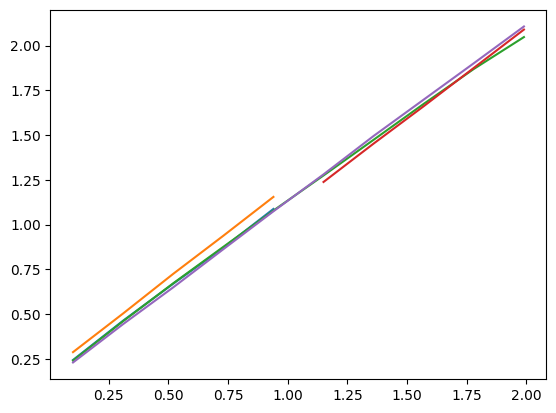

In [4]:
from andi_datasets.datasets_theory import datasets_theory
from andi_datasets.utils_trajectories import normalize

DT = datasets_theory()

T = 50; N = 100
models = np.arange(5)
models_alpha = ['sub', 'sub', 'all', 'super', 'all']

mae = []

num_exponents = 10
mse_exponent = np.zeros((len(models), num_exponents))
BATCH_SIZE = 512  # run inference in chunks to avoid GPU OOM
all_exponents = np.linspace(0.1, 1.99, num_exponents)
for idxm, model in enumerate(tqdm(models)):
    if models_alpha[model] == 'sub':
        idx_exps = np.where(all_exponents <= 1)[0]
        exponents = all_exponents[idx_exps]
    elif models_alpha[model] == 'super':
        idx_exps = np.where(all_exponents >= 1)[0]
        exponents = all_exponents[idx_exps]
    elif models_alpha[model] == 'all':
        idx_exps = np.arange(num_exponents)
        exponents = all_exponents[idx_exps]

    # if idxm == 0:
    #     continue

    dataset = DT.create_dataset(T = T, N_models = N, exponents = exponents.tolist(), models = [model], dimension = 2)

    n_traj = dataset.shape[0]
    norm_trajs = normalize(dataset[:, 2:].reshape(n_traj*2, T)).reshape(dataset[:, 2:].shape)
    dataset[:, 2:] = norm_trajs.reshape(dataset[:, 2:].shape)

    inputs = dataset[:, 2:].reshape(-1, 2, T).transpose(0,2,1)
    inputs += np.random.randn(*inputs.shape) * 0.01
    polar_np = cartesian_to_relative_polar(inputs)  # keep on CPU

    # Batched inference to avoid GPU OOM
    n = len(polar_np)
    pred_list = []
    model_single.eval()
    with torch.no_grad():
        for start in range(0, n, BATCH_SIZE):
            chunk = torch.tensor(polar_np[start:start+BATCH_SIZE], dtype=torch.float).to(dvc)
            pred_list.append(model_single(chunk).cpu().numpy().flatten())
            del chunk
    pred = np.concatenate(pred_list)

    maes = np.abs(pred - dataset[:, 1])

    mae.append(float(np.mean(maes)))

    mse_exponent[idxm, idx_exps] = maes.reshape(len(idx_exps), N).mean(1)

    # print(DT.avail_models_name[idxm], 'exps:', exponents)
    # # print(pred.reshape(len(idx_exps), N).mean(1).round(2))
    # print(mse_exponent[idxm, idx_exps] .round(2))
    avg = round(float(mse_exponent[idxm, idx_exps].mean()), 3)
    result = {round(e, 2): round(v, 2) for e, v in zip(exponents, mse_exponent[idxm, idx_exps])}
    print(f"{DT.avail_models_name[idxm]} (avg={avg}): {result}")

    plt.plot(exponents, maes.reshape(len(idx_exps), N).mean(1), label = DT.avail_models_name[idxm])

print(mae)


In [35]:
X1, Y1, X2, Y2, X3, Y3 = challenge_theory_dataset(N = 5000, tasks = 1, dimensions = 2,
                                            min_T = 10, max_T = 200, load_dataset = False)

# Prepare data in polar representation
inputs = X1[1]
outputs = torch.tensor(Y1[1]).to(dvc)

tensor_X = []
for i in inputs:
    traj = torch.tensor(i).reshape(2, -1).T.unsqueeze(0) # This gives a tensor of shape (1, T, 2) for each trajectory, where T is the length of the trajectory. 
    tensor_X.append(traj)
lengths = [t.shape[1] for t in tensor_X]
polar_X = [torch.tensor(cartesian_to_relative_polar(traj), dtype=torch.float).to(dvc) for traj in tensor_X]


Creating a dataset for task(s) 1 and dimension(s) 2.
Generating dataset for dimension 2.


In [36]:

preds = []
for traj in polar_X:
    pred = model_single(traj)
    preds.append(pred)
preds = torch.cat(preds).flatten()

In [50]:
num_exponents = 10
exponents = np.linspace(0, 1.99, num_exponents)
mae_exp = np.zeros(num_exponents-1)
for exp in range(1, num_exponents):
    idx = torch.where((exponents[exp-1] < outputs) & (outputs <= exponents[exp]))
    mae_exp[exp-1] = (preds[idx]-outputs[idx]).abs().mean()


In [ ]:
exponen

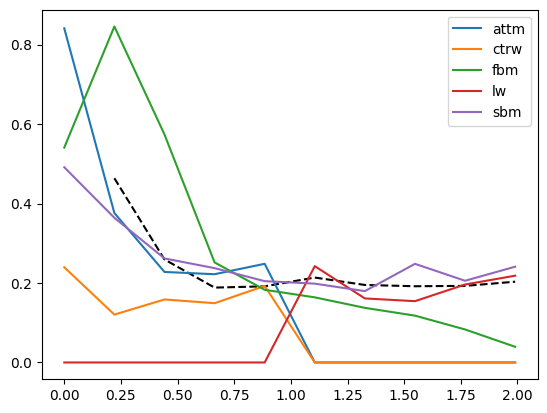

In [51]:
plt.plot(exponents[1:], mae_exp, c = 'k', ls = '--')
plt.plot(exponents, mse_exponent.T, label = DT.avail_models_name)
plt.legend()

### Benchmarking againts just STEP output avg

In [3]:
# STEPalpha: Anomalous exponent model
model_kistep = XResAttn(2, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
             block_szs=[128, 256, 512], dropout=0., pos_enc=False, n_encoder_layers=4,
             dim_ff=512, nhead_enc=8, norm=False, linear_layers=[],yrange=(-0.1,2.1)).to('cuda')

model_kistep.load_state_dict(torch.load('../model_weights/xresattn_alpha_2d_varlen_relpolar_yrange_m01_21_big22E2.pth')['model'])
model_kistep.eval();


In [10]:
pred.mean().cpu()

tensor(0.8542)

In [27]:
preds_step = []
for traj in tqdm(polar_X):
    with torch.no_grad():
        pred = model_kistep(traj).median().cpu()
    preds_step.append(pred)
preds_step = torch.stack(preds_step).flatten()

  0%|          | 0/5000 [00:00<?, ?it/s]

In [28]:
num_exponents = 20
exponents = np.linspace(0, 1.99, num_exponents)
mae_exp_step = np.zeros(num_exponents-1)
for exp in range(1, num_exponents):
    idx = torch.where((exponents[exp-1] < outputs.cpu()) & (outputs.cpu() <= exponents[exp]))
    mae_exp_step[exp-1] = (preds_step[idx]-outputs.cpu()[idx]).abs().mean()


In [29]:
mae_exp.mean(), mae_exp_step.mean()

(0.23046318837095772, 0.4316948136597551)

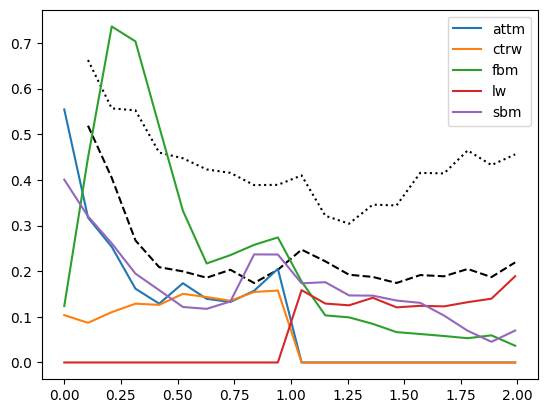

In [30]:
plt.plot(exponents[1:], mae_exp, c = 'k', ls = '--')
plt.plot(exponents[1:], mae_exp_step, c = 'k', ls = ':')
plt.plot(exponents, mse_exponent.T, label = DT.avail_models_name)
plt.legend()

# EXP LONG 21

In [5]:
import torch
import torch.nn.functional as F
import math
import torch.nn as nn
from step.models import XResAttn

class ResBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim), nn.GELU())
    def forward(self, x): return x + self.net(x)

class SingleTrajModel(nn.Module):
    """Frozen XResAttn + per-layer dual-attn pooling + log(T) → residual MLP head."""
    def __init__(self, backbone, dropout=0.0, freeze_backbone=True):
        super().__init__()
        self.backbone = backbone
        if freeze_backbone:
            self.backbone.requires_grad_(False)
        self.backbone.eval()
        self.drop = nn.Dropout(dropout)
        hidden_dim = backbone.encoder.layers[0].self_attn.embed_dim
        n_layers = len(backbone.encoder.layers)
        self.attn_queries = nn.ModuleList([
            nn.Linear(hidden_dim, 2, bias=False) for _ in range(n_layers)
        ])
        feat_dim = hidden_dim * n_layers * 3 + 12  # mean+2attn; +7 physics +2 interactions +1 Q1vsQ4 +1 log_var_dr_ratio +1 log_kurtosis
        self.head = nn.Sequential(
                    nn.LayerNorm(feat_dim),
                    nn.Linear(feat_dim, 512),
                    nn.GELU(),
                    ResBlock(512),
                    nn.LayerNorm(512),
                    nn.Linear(512, 256),
                    nn.GELU(),
                    nn.Linear(256, 1)
                )

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()
        return self

    def forward(self, x):
        T = x.shape[1]
        dtheta = x[:, :, 1]
        dr = x[:, :, 0]
        mean_cos_dth = dtheta.cos().mean(dim=1, keepdim=True)
        frac_large_turn = (dtheta.abs() > (math.pi / 2)).float().mean(dim=1, keepdim=True)
        half = T // 2
        log_dr_trend = torch.log(dr[:, half:].mean(dim=1, keepdim=True).clamp(min=1e-8) /
                                 dr[:, :half].mean(dim=1, keepdim=True).clamp(min=1e-8))
        mean_dr = dr.mean(dim=1, keepdim=True).clamp(min=1e-8)
        cv_dr = dr.std(dim=1, keepdim=True) / mean_dr
        frac_above_mean = (dr > mean_dr).float().mean(dim=1, keepdim=True)
        x = self.backbone.norm(x)
        x = self.backbone.convs(x.transpose(2, 1)).transpose(2, 1)
        src = self.backbone.pos_enc(x.transpose(1, 0))
        layer_outputs = []
        y = src
        for layer in self.backbone.encoder.layers:
            y = layer(y)
            layer_outputs.append(y.transpose(0, 1))
        layer_pools = []
        for i, z in enumerate(layer_outputs):
            scores = self.attn_queries[i](z)
            weights = F.softmax(scores, dim=1)
            layer_pools.append(z.mean(dim=1))
            layer_pools.append((z * weights[:, :, 0:1]).sum(dim=1))
            layer_pools.append((z * weights[:, :, 1:2]).sum(dim=1))
        out = torch.cat(layer_pools, dim=1)
        out = self.drop(out)
        log_t = torch.full((out.shape[0], 1), math.log(T), device=out.device)
        inv_t = torch.full((out.shape[0], 1), 1.0 / T, device=out.device)
        q1 = max(T // 4, 1)
        log_dr_Q1_Q4 = torch.log(dr[:, -q1:].mean(dim=1, keepdim=True).clamp(min=1e-8) /
                                  dr[:, :q1].mean(dim=1, keepdim=True).clamp(min=1e-8))
        interact_attm = cv_dr * frac_above_mean
        interact_sbm = log_dr_trend * (1.0 - frac_above_mean)
        # log-kurtosis: log(E[dr^4]/E[dr^2]^2); Gaussian(2D)→log(2)≈0.693; heavy-tail>>log(2)
        # LSE trick prevents fp32 overflow from large LW step sizes
        log_dr = torch.log(dr.clamp(min=1e-8))
        _v4 = 4 * log_dr; _m4 = _v4.max(dim=1, keepdim=True).values
        _v2 = 2 * log_dr; _m2 = _v2.max(dim=1, keepdim=True).values
        log_kurtosis = ((_m4 + torch.log((_v4 - _m4).exp().mean(dim=1, keepdim=True).clamp(min=1e-8))) -
                        2 * (_m2 + torch.log((_v2 - _m2).exp().mean(dim=1, keepdim=True).clamp(min=1e-8))))
        # SBM: D(t)~t^(a-1) → variance of dr also changes; subdiff a<1 → var ratio < 0
        log_var_dr_ratio = torch.log(dr[:, half:].var(dim=1, keepdim=True).clamp(min=1e-8) /
                                     dr[:, :half].var(dim=1, keepdim=True).clamp(min=1e-8))
        out = torch.cat([out, log_t, inv_t, mean_cos_dth, frac_large_turn, log_dr_trend, cv_dr, frac_above_mean, interact_attm, interact_sbm, log_dr_Q1_Q4, log_var_dr_ratio, log_kurtosis], dim=1)
        return self.head(out)

In [6]:
# 1. Recreate the architecture (see train_long.py for full definition)
backbone = XResAttn(2, n_class=1, stem_szs=(32,), conv_blocks=[1,1,1],
                    block_szs=[128,256,512], dropout=0., pos_enc=False,
                    n_encoder_layers=4, dim_ff=512, nhead_enc=8,
                    norm=False, linear_layers=[])
model_single = SingleTrajModel(backbone, dropout=0.1, freeze_backbone=False).to('cuda')

# 2. Load weights
state = torch.load('models/kistep_adapted_single_long_exp21.pth', map_location='cuda')
model_single.load_state_dict(state)
model_single.eval();

In [9]:
Ts = np.arange(10, 1000, 50);
Ts.shape

(20,)

In [19]:
from andi_datasets.datasets_theory import datasets_theory
from andi_datasets.utils_trajectories import normalize

DT = datasets_theory()

N = 100
models = np.arange(5)
models_alpha = ['sub', 'sub', 'all', 'super', 'all']



num_exponents = 10
mse_exponent = np.zeros((len(models), num_exponents))
BATCH_SIZE = 64  # run inference in chunks to avoid GPU OOM
all_exponents = np.linspace(0.1, 1.99, num_exponents)


Ts = np.arange(10, 1000, 50);
mae_T = np.zeros(len(Ts))
for idxt, T in enumerate(Ts):

    mae = []
    for idxm, model in enumerate(tqdm(models)):
        if models_alpha[model] == 'sub':
            idx_exps = np.where(all_exponents <= 1)[0]
            exponents = all_exponents[idx_exps]
        elif models_alpha[model] == 'super':
            idx_exps = np.where(all_exponents >= 1)[0]
            exponents = all_exponents[idx_exps]
        elif models_alpha[model] == 'all':
            idx_exps = np.arange(num_exponents)
            exponents = all_exponents[idx_exps]

        # if idxm == 0:
        #     continue

        dataset = DT.create_dataset(T = T, N_models = N, exponents = exponents.tolist(), models = [model], dimension = 2)

        n_traj = dataset.shape[0]
        norm_trajs = normalize(dataset[:, 2:].reshape(n_traj*2, T)).reshape(dataset[:, 2:].shape)
        dataset[:, 2:] = norm_trajs.reshape(dataset[:, 2:].shape)

        inputs = dataset[:, 2:].reshape(-1, 2, T).transpose(0,2,1)
        inputs += np.random.randn(*inputs.shape) * 0.001
        polar_np = cartesian_to_relative_polar(inputs)  # keep on CPU

        # Batched inference to avoid GPU OOM
        n = len(polar_np)
        pred_list = []
        model_single.eval()
        with torch.no_grad():
            for start in range(0, n, BATCH_SIZE):
                chunk = torch.tensor(polar_np[start:start+BATCH_SIZE], dtype=torch.float).to(dvc)
                pred_list.append(model_single(chunk).cpu().numpy().flatten())
                del chunk
        pred = np.concatenate(pred_list)

        maes = np.abs(pred - dataset[:, 1])

        mae.append(float(np.mean(maes)))

        mse_exponent[idxm, idx_exps] = maes.reshape(len(idx_exps), N).mean(1)

        # print(DT.avail_models_name[idxm], 'exps:', exponents)
        # # print(pred.reshape(len(idx_exps), N).mean(1).round(2))
        # print(mse_exponent[idxm, idx_exps] .round(2))
        avg = round(float(mse_exponent[idxm, idx_exps].mean()), 3)
        result = {round(e, 2): round(v, 2) for e, v in zip(exponents, mse_exponent[idxm, idx_exps])}
    #     print(f"{DT.avail_models_name[idxm]} (avg={avg}): {result}")

    #     plt.plot(exponents, maes.reshape(len(idx_exps), N).mean(1), label = DT.avail_models_name[idxm])
    mae_T[idxt] = float(np.mean(mae))
    # print(mae)


  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

...

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

  0%|          | 0/5 [00:00<?, ?it/s]

In [20]:
np.mean(mae_T)

0.1536510062528908

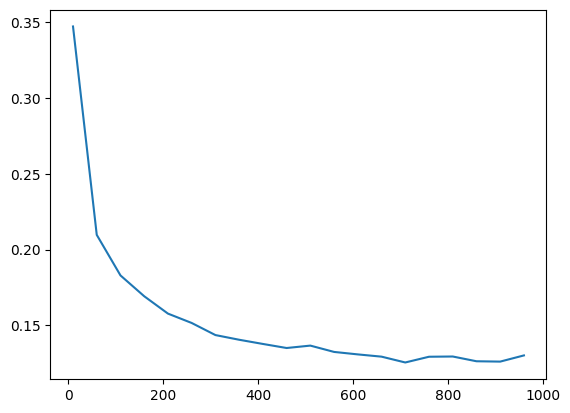

In [21]:
plt.plot(Ts, mae_T)

# EXP with models 14

In [2]:
class ResBlock(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(dim), nn.Linear(dim, dim), nn.GELU())
    def forward(self, x): return x + self.net(x)


class V2CombinedModel(nn.Module):
    """
    Frozen Cls-Exp17 backbone + pooling + shared_encoder + cls_head
    + 5 per-type alpha regressors.

    Forward -> (B, 11):
      cols 0-4  : per-type alpha predictions
      cols 5-9  : cls logits
      col  10   : soft-routed alpha (sum of softmax(logits) * per-type preds)
    """
    def __init__(self, backbone, n_models=5, dropout=0.1):
        super().__init__()
        self.backbone = backbone
        self.drop = nn.Dropout(dropout)

        hidden_dim = backbone.encoder.layers[0].self_attn.embed_dim  # 512
        n_layers   = len(backbone.encoder.layers)                     # 4
        self.attn_queries = nn.ModuleList([
            nn.Linear(hidden_dim, 2, bias=False) for _ in range(n_layers)
        ])
        feat_dim = hidden_dim * n_layers * 3 + 12  # 6156
        self.shared_encoder = nn.Sequential(
            nn.LayerNorm(feat_dim), nn.Linear(feat_dim, 512), nn.GELU(), ResBlock(512)
        )
        self.cls_head = nn.Sequential(
            nn.LayerNorm(512), nn.Dropout(dropout),
            nn.Linear(512, 256), nn.GELU(), nn.Linear(256, n_models)
        )
        self.regressors = nn.ModuleList([
            nn.Sequential(nn.LayerNorm(512), nn.Linear(512, 128), nn.GELU(), nn.Linear(128, 1))
            for _ in range(n_models)
        ])

    def forward(self, x):
        T      = x.shape[1]
        dr_max = x[:, :, 0].max(dim=1, keepdim=True).values.clamp(min=1e-8)
        x      = x.clone()
        x[:, :, 0] = x[:, :, 0] / dr_max
        dtheta = x[:, :, 1]
        dr     = x[:, :, 0]

        mean_cos_dth    = dtheta.cos().mean(dim=1, keepdim=True)
        frac_large_turn = (dtheta.abs() > (math.pi / 2)).float().mean(dim=1, keepdim=True)
        half            = T // 2
        log_dr_trend    = torch.log(dr[:, half:].mean(dim=1, keepdim=True).clamp(min=1e-8) /
                                    dr[:, :half].mean(dim=1, keepdim=True).clamp(min=1e-8))
        mean_dr         = dr.mean(dim=1, keepdim=True).clamp(min=1e-8)
        cv_dr           = dr.std(dim=1, keepdim=True) / mean_dr
        frac_above_mean = (dr > mean_dr).float().mean(dim=1, keepdim=True)
        q1              = max(T // 4, 1)
        log_dr_Q1_Q4    = torch.log(dr[:, -q1:].mean(dim=1, keepdim=True).clamp(min=1e-8) /
                                    dr[:, :q1].mean(dim=1, keepdim=True).clamp(min=1e-8))
        interact_attm   = cv_dr * frac_above_mean
        interact_sbm    = log_dr_trend * (1.0 - frac_above_mean)
        log_var_dr_ratio = torch.log(dr[:, half:].var(dim=1, keepdim=True).clamp(min=1e-8) /
                                     dr[:, :half].var(dim=1, keepdim=True).clamp(min=1e-8))
        log_dr_f = torch.log(dr.clamp(min=1e-8))
        _v4 = 4 * log_dr_f; _m4 = _v4.max(dim=1, keepdim=True).values
        _v2 = 2 * log_dr_f; _m2 = _v2.max(dim=1, keepdim=True).values
        log_kurtosis = ((_m4 + torch.log((_v4 - _m4).exp().mean(dim=1, keepdim=True).clamp(min=1e-8))) -
                        2 * (_m2 + torch.log((_v2 - _m2).exp().mean(dim=1, keepdim=True).clamp(min=1e-8))))

        xb  = self.backbone.norm(x)
        xb  = self.backbone.convs(xb.transpose(2, 1)).transpose(2, 1)
        src = self.backbone.pos_enc(xb.transpose(1, 0))
        y   = src
        layer_outputs = []
        for layer in self.backbone.encoder.layers:
            y = layer(y)
            layer_outputs.append(y.transpose(0, 1))

        layer_pools = []
        for i, z in enumerate(layer_outputs):
            scores  = self.attn_queries[i](z)
            weights = F.softmax(scores, dim=1)
            layer_pools.append(z.mean(dim=1))
            layer_pools.append((z * weights[:, :, 0:1]).sum(dim=1))
            layer_pools.append((z * weights[:, :, 1:2]).sum(dim=1))
        out = torch.cat(layer_pools, dim=1)
        out = self.drop(out)

        log_t    = torch.full((out.shape[0], 1), math.log(T), device=out.device)
        inv_t    = torch.full((out.shape[0], 1), 1.0 / T,    device=out.device)
        features = torch.cat([out, log_t, inv_t, mean_cos_dth, frac_large_turn,
                               log_dr_trend, cv_dr, frac_above_mean, interact_attm,
                               interact_sbm, log_dr_Q1_Q4, log_var_dr_ratio, log_kurtosis], dim=1)

        shared     = self.shared_encoder(features)
        logits     = self.cls_head(shared)
        probs      = F.softmax(logits, dim=-1)
        reg_out    = torch.cat([reg(shared) for reg in self.regressors], dim=1)
        soft_alpha = (probs * reg_out).sum(dim=1, keepdim=True)
        return torch.cat([reg_out, logits, soft_alpha], dim=1)

In [4]:
backbone = XResAttn(
    2, n_class=1, stem_szs=(32,), conv_blocks=[1, 1, 1],
    block_szs=[128, 256, 512], dropout=0., pos_enc=False,
    n_encoder_layers=4, dim_ff=512, nhead_enc=8, norm=False, linear_layers=[]
)

MODEL_PATH = 'models/V2-Exp14_model.pth'
model_single = V2CombinedModel(backbone, n_models=5, dropout=0.1).to(dvc)
model_single.load_state_dict(torch.load(MODEL_PATH, map_location=dvc))
model_single.eval()
print(f'Loaded {MODEL_PATH}')
total = sum(p.numel() for p in model_single.parameters())
print(f'Parameters: {total:,}')

Loaded models/V2-Exp14_model.pth
Parameters: 11,924,258


  0%|          | 0/5 [00:00<?, ?it/s]

0
attm (avg=0.323): {0.1: 0.65, 0.31: 0.27, 0.52: 0.17, 0.73: 0.21, 0.94: 0.32}
1
ctrw (avg=0.185): {0.1: 0.12, 0.31: 0.12, 0.52: 0.13, 0.73: 0.2, 0.94: 0.36}
2
fbm (avg=0.185): {0.1: 0.07, 0.31: 0.1, 0.52: 0.09, 0.73: 0.08, 0.94: 0.15, 1.15: 0.24, 1.36: 0.19, 1.57: 0.26, 1.78: 0.41, 1.99: 0.26}
3
lw (avg=0.201): {1.15: 0.22, 1.36: 0.13, 1.57: 0.13, 1.78: 0.2, 1.99: 0.32}
4
sbm (avg=0.305): {0.1: 0.14, 0.31: 0.12, 0.52: 0.13, 0.73: 0.11, 0.94: 0.17, 1.15: 0.25, 1.36: 0.28, 1.57: 0.39, 1.78: 0.55, 1.99: 0.91}


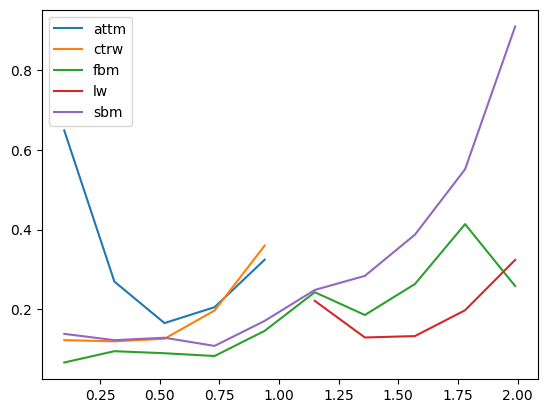

In [30]:
from andi_datasets.datasets_theory import datasets_theory
from andi_datasets.utils_trajectories import normalize

DT = datasets_theory()

T = 50; N = 100
models = np.arange(5)
models_alpha = ['sub', 'sub', 'all', 'super', 'all']

mae = []

num_exponents = 10
mse_exponent = np.zeros((len(models), num_exponents))
BATCH_SIZE = 512  # run inference in chunks to avoid GPU OOM
all_exponents = np.linspace(0.1, 1.99, num_exponents)
for idxm, model in enumerate(tqdm(models)):

    print(model)
    if models_alpha[model] == 'sub':
        idx_exps = np.where(all_exponents <= 1)[0]
        exponents = all_exponents[idx_exps]
    elif models_alpha[model] == 'super':
        idx_exps = np.where(all_exponents >= 1)[0]
        exponents = all_exponents[idx_exps]
    elif models_alpha[model] == 'all':
        idx_exps = np.arange(num_exponents)
        exponents = all_exponents[idx_exps]

    # if idxm == 0:
    #     continue

    dataset = DT.create_dataset(T = T, N_models = N, exponents = exponents.tolist(), models = [model], dimension = 2)

    n_traj = dataset.shape[0]
    norm_trajs = normalize(dataset[:, 2:].reshape(n_traj*2, T)).reshape(dataset[:, 2:].shape)
    dataset[:, 2:] = norm_trajs.reshape(dataset[:, 2:].shape)

    inputs = dataset[:, 2:].reshape(-1, 2, T).transpose(0,2,1)
    inputs += np.random.randn(*inputs.shape) * 0.01
    polar_np = cartesian_to_relative_polar(inputs)  # keep on CPU

    # Batched inference to avoid GPU OOM
    pred, _, _ = run_inference_batch(model_single, [torch.tensor(polar, dtype=torch.float32) for polar in polar_np], batch_size=256)

    maes = np.abs(pred - dataset[:, 1])
    

    mae.append(float(np.mean(maes)))

    mse_exponent[idxm, idx_exps] = maes.reshape(len(idx_exps), N).mean(1)

    # print(DT.avail_models_name[idxm], 'exps:', exponents)
    # # print(pred.reshape(len(idx_exps), N).mean(1).round(2))
    # print(mse_exponent[idxm, idx_exps] .round(2))
    avg = round(float(mse_exponent[idxm, idx_exps].mean()), 3)
    result = {round(e, 2): round(v, 2) for e, v in zip(exponents, mse_exponent[idxm, idx_exps])}
    print(f"{DT.avail_models_name[idxm]} (avg={avg}): {result}")

    plt.plot(exponents, maes.reshape(len(idx_exps), N).mean(1), label = DT.avail_models_name[idxm])

plt.legend()


In [12]:
def run_inference_batch(model, polar_list, batch_size=256):
    """All tensors in polar_list have the same shape (T-1, 2). Returns alpha + class predictions."""
    n = len(polar_list)
    preds = np.zeros(n, dtype=np.float32)
    cls_preds = np.zeros(n, dtype=np.int32)
    cls_probs = np.zeros((n, 5), dtype=np.float32)

    with torch.no_grad():
        for i in range(0, n, batch_size):
            batch = torch.stack(polar_list[i:i + batch_size]).to(dvc)
            out = model(batch)
            out_cpu = out.cpu()
            for j in range(out_cpu.shape[0]):
                idx = i + j
                preds[idx] = float(out_cpu[j, 10])
                probs = F.softmax(out_cpu[j, 5:10], dim=0).numpy()
                cls_probs[idx] = probs
                cls_preds[idx] = int(probs.argmax())

    return preds, cls_preds, cls_probs

In [ ]:
from andi_datasets.datasets_challenge import challenge_theory_dataset

X1, Y1, X2, Y2, X3, Y3 = challenge_theory_dataset(N = 1000, tasks = [1,2], dimensions = 2, min_T = 10, max_T = 200, load_dataset = False)

# Prepare data in polar representation
inputs_alpha = X1[1]
inputs_model = X2[1]


polar_X_alpha = []
polar_X_model = []
for i_a, i_m in zip(inputs_alpha, inputs_model):
    traj_a = torch.tensor(i_a).reshape(2, -1).T.unsqueeze(0)
    polar_X_alpha.append(torch.tensor(cartesian_to_relative_polar(traj_a), dtype=torch.float).to(dvc))

    traj_m = torch.tensor(i_m).reshape(2, -1).T.unsqueeze(0)
    polar_X_model.append(torch.tensor(cartesian_to_relative_polar(traj_m), dtype=torch.float).to(dvc))

ae = []
acc = []
with torch.no_grad():
    for traj_a, true_a, traj_m, true_m in zip(tqdm(polar_X_alpha), Y1[1], polar_X_model, Y2[1]):

        out = model_single(traj_a).cpu()[0]
        ae.append(np.abs(float(out[10])-true_a))
        
        out = model_single(traj_m).cpu()[0]
        pred = int(F.softmax(out[5:10], dim=0).numpy().argmax())
        acc.append(pred == true_m) 

print(np.mean(ae), np.mean(acc))


Creating a dataset for task(s) [1, 2] and dimension(s) 2.
Generating dataset for dimension 2.


  0%|          | 0/1000 [00:00<?, ?it/s]

0.629

In [63]:
print(np.mean(ae), np.mean(acc))

0.3469540173977614 0.629


In [ ]:
# Prepare data in polar representation
c

tensor_X = []
for i in inputs:
    traj = torch.tensor(i).reshape(2, -1).T.unsqueeze(0) # This gives a tensor of shape (1, T, 2) for each trajectory, where T is the length of the trajectory. 
    tensor_X.append(traj)
lengths = [t.shape[1] for t in tensor_X]
polar_X = [torch.tensor(cartesian_to_relative_polar(traj), dtype=torch.float).to(dvc) for traj in tensor_X]

In [ ]:
acc = []

with torch.no_grad():
    for traj, true in zip(tqdm(polar_X), Y2[1]):
        pred = model_single(traj)

        out = model_single(traj)
        out_cpu = out.cpu()[0]
        pred = int(F.softmax(out_cpu[5:10], dim=0).numpy().argmax())
        acc.append(pred == true)    

np.mean(acc)
        

  0%|          | 0/1000 [00:00<?, ?it/s]

0.606